# 2.03 — MiBici hyperparameter tuning: time-based validation and nested MLflow runs

**Phase 2 (model building)** following the [Cookiecutter Data Science](https://cookiecutter-data-science.drivendata.org/using-the-template/) convention: `PHASE.NOTEBOOK-initials-description`. It runs after `2.02`, which chose the two finalists `lgbm_tweedie` and `hgb_poisson`.

- **Input:** the MLflow runs of `python -m team2_mlops2026.modeling.train tune` (about 4 hours on a laptop): one parent run `tune-<model>-<target>` per finalist and target, with one nested run per trial. The search reads `station_hour_features.parquet` and `station_profiles.parquet`, as `2.02` does.
- **Output:** the tuned params of each finalist and target, and the refitted models logged in the parent runs, ready for the backtest (`2.04`).

**Why.** `2.02` compared the candidates with their library defaults. Tuning searches for better params without looking at the test months (2025-10 to 2026-09): every trial is validated on the last three months of the training split, and the test months stay untouched for the backtest. The [ML Canvas](../references/ml-canvas.md) (§8) records the choices: random search, Poisson deviance as the objective, and a random third of each fold's hours as the compute budget.

1. The search space and the time-based folds.
2. Read the search back from MLflow and check its lineage.
3. Parallel coordinates of the trials.
4. Contour plots of the two main params.
5. The effect of each hyperparameter.
6. Defaults against tuned: the acceptance criterion.
7. Check the refitted models logged in the parent runs.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"  # keep the outputs readable

import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient
import numpy as np
import pandas as pd

from team2_mlops2026 import plots
from team2_mlops2026.config import MLFLOW_EXPERIMENT_NAME, MLFLOW_TRACKING_URI
from team2_mlops2026.features import RUN_NAME as FEATURES_RUN
from team2_mlops2026.features import SEED, TARGETS
from team2_mlops2026.modeling.evaluate import TEST_START
from team2_mlops2026.modeling.models import MODELS
from team2_mlops2026.modeling.train import (
    MODEL_ARTIFACT,
    RUN_PREFIX as TRAIN_PREFIX,
    load_features,
    model_inputs,
    model_params,
)
from team2_mlops2026.modeling.tuning import (
    DEFAULTS_RUN,
    FINALISTS,
    ITERATIONS,
    OBJECTIVE,
    RUN_PREFIX,
    VALIDATION_METRICS,
    search_space_table,
    tuning_folds,
)
from team2_mlops2026.station_profiles import RUN_NAME as PROFILES_RUN
from team2_mlops2026.tracking import input_digests

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
plots.use_style()
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
client = MlflowClient()

C:\MLOpsRepos\Proyecto\team2_mlops2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-11-07 03:51:33.864 | INFO     | team2_mlops2026.config:<module>:12 - PROJ_ROOT path is: C:\MLOpsRepos\Proyecto\team2_mlops2026


## Parameters

`OBJECTIVE` is the mean validation Poisson deviance over the folds. The other validation metrics are logged for every trial, so the choice can be checked against the WAPE of the success criterion.

In [3]:
VAL_METRICS = [f"val_{m}" for m in VALIDATION_METRICS]
KEYS = [(name, target) for name in FINALISTS for target in TARGETS]
# The two params of each model shown in the contour plots: step size and tree size
CONTOUR = {"lgbm_tweedie": ("learning_rate", "num_leaves"), "hgb_poisson": ("learning_rate", "max_leaf_nodes")}
CHECK_MONTH = "2025-09"  # last training month: the logged models are checked on its hours

## 1. The search space and the folds

The search space lives in each model's `ModelSpec` (`modeling/models.py`). It covers the step size, the tree size, the minimum rows per leaf, L2 regularization, the row and column sampling of LightGBM, the Tweedie variance power, and the maximum number of boosting iterations. The `default` column is trial 0: the params `2.02` trained with.

The step size and the penalties are drawn on a log scale (`loguniform`), since their effect is multiplicative. The counts are drawn uniformly (`randint`).

In [4]:
pd.concat({name: search_space_table(MODELS[name]) for name in FINALISTS}, names=["model"])

distribution     low high default
model        param                                                   
lgbm_tweedie n_estimators                randint     100  799     100
             learning_rate            loguniform    0.02  0.3     0.1
             num_leaves                  randint      15  254      31
             min_child_samples           randint      20  499      20
             subsample                   uniform     0.5  1.0     1.0
             colsample_bytree            uniform     0.5  1.0     1.0
             reg_lambda               loguniform  0.0001   10     0.0
             tweedie_variance_power      uniform     1.1  1.9     1.5
hgb_poisson  learning_rate            loguniform    0.02  0.3     0.1
             max_iter                    randint     100  599     100
             max_leaf_nodes              randint      15  127      31
             min_samples_leaf            randint      20  499      20
             l2_regularization        loguniform  0.0001   10     0.0

Every trial is scored on three time-ordered folds inside the training split. Each fold fits on the window's hours before its month (a random third of them) and stops early on the 14 days just before the month. It never sees an hour after the one it is validated on, and no fold reaches the test split, which starts in 2025-10. `tests/test_tuning.py` checks both properties.

In [5]:
folds = tuning_folds()
pd.DataFrame(
    {
        "fit": f"{f.fit_start:%Y-%m-%d} to {f.stop_start - pd.Timedelta(hours=1):%Y-%m-%d %H:00}",
        "early stopping": f"{f.stop_start:%Y-%m-%d} to {f.val_start - pd.Timedelta(hours=1):%Y-%m-%d %H:00}",
        "validation": f"{f.val_start:%Y-%m-%d} to {f.val_end - pd.Timedelta(hours=1):%Y-%m-%d %H:00}",
    }
    for f in folds
).set_axis([str(f.month) for f in folds]).rename_axis("fold")

,fit,early stopping,validation
fold,,,
2025-07,2024-10-01 to 2025-06-16 23:00,2025-06-17 to 2025-06-30 23:00,2025-07-01 to 2025-07-31 23:00
2025-08,2024-10-01 to 2025-07-17 23:00,2025-07-18 to 2025-07-31 23:00,2025-08-01 to 2025-08-31 23:00
2025-09,2024-10-01 to 2025-08-17 23:00,2025-08-18 to 2025-08-31 23:00,2025-09-01 to 2025-09-30 23:00


## 2. The search in MLflow

The notebook reads the latest finished parent run of each finalist and target, and the trials nested under it. In the MLflow UI they are the runs `tune-<model>-<target>`: expanding one shows its 21 trials (`defaults`, `trial-01`... `trial-20`).

In [6]:
parents = {
    (name, target): mlflow.search_runs(
        experiment_names=[MLFLOW_EXPERIMENT_NAME],
        filter_string=f"tags.mlflow.runName = '{RUN_PREFIX}-{name}-{target}' and status = 'FINISHED'",
        order_by=["start_time DESC"],
        max_results=1,
        output_format="list",
    )[0]
    for name, target in KEYS
}
trial_runs = {
    key: mlflow.search_runs(
        experiment_names=[MLFLOW_EXPERIMENT_NAME],
        filter_string=f"tags.mlflow.parentRunId = '{run.info.run_id}'",
    )
    for key, run in parents.items()
}
for key, runs in trial_runs.items():
    assert len(runs) == int(parents[key].data.params["n_trials"]) + 1
    assert (runs["status"] == "FINISHED").all()
    # The parent's best trial is the one with the lowest objective
    best = runs.loc[runs[f"metrics.{OBJECTIVE}"].idxmin(), "tags.trial"]
    assert best == parents[key].data.params["best_trial"]

pd.DataFrame(
    {
        key: {
            "parent run": run.info.run_id,
            "trials": len(trial_runs[key]),
            "best trial": int(run.data.params["best_trial"]),
            "validation months": run.data.params["validation_months"],
            "fit sample": run.data.params["fit_sample"],
            "search hours": round(trial_runs[key]["metrics.fit_seconds"].sum() / 3600, 2),
            "refit (s)": round(run.data.metrics["fit_seconds"]),
        }
        for key, run in parents.items()
    }
).T.rename_axis(["model", "target"])

parent run trials best trial  \
model        target                                                           
lgbm_tweedie departures  b5263556599c4adaa50ccf632e17c2eb     21         13   
             arrivals    08ab23db7bb84a75ae1a31a77148ca9c     21         16   
hgb_poisson  departures  5cbc27a4022e41e09b1ead845e191b2e     21          2   
             arrivals    05e37fa40e724627b02fbe6c585c7033     21         20   

                               validation months fit sample search hours  \
model        target                                                        
lgbm_tweedie departures  2025-07,2025-08,2025-09      0.333        13.78   
             arrivals    2025-07,2025-08,2025-09      0.333         0.59   
hgb_poisson  departures  2025-07,2025-08,2025-09      0.333         0.91   
             arrivals    2025-07,2025-08,2025-09      0.333         0.87   

                        refit (s)  
model        target                
lgbm_tweedie departures       820  
             arrivals         311  
hgb_poisson  departures       367  
             arrivals         617

Every parent run logs the feature and profile tables as inputs. Their digests must be those of the latest pipeline runs, so the search used the same data as `2.02`.

In [7]:
upstream = {}
for run_name in (FEATURES_RUN, PROFILES_RUN):
    latest = mlflow.search_runs(
        experiment_names=[MLFLOW_EXPERIMENT_NAME],
        filter_string=f"tags.mlflow.runName = '{run_name}' and status = 'FINISHED'",
        order_by=["start_time DESC"],
        max_results=1,
        output_format="list",
    )[0]
    upstream |= input_digests(latest.info.run_id)

lineage = pd.DataFrame({f"{n} / {t}": input_digests(r.info.run_id) for (n, t), r in parents.items()})
assert lineage.eq(pd.Series(upstream).reindex(lineage.index), axis=0).all().all()
lineage

,lgbm_tweedie / departures,lgbm_tweedie / arrivals,hgb_poisson / departures,hgb_poisson / arrivals
mibici_station_hour_features,1de2638d6929153bce7034f39baaade9,1de2638d6929153bce7034f39baaade9,1de2638d6929153bce7034f39baaade9,1de2638d6929153bce7034f39baaade9
mibici_station_profiles,fe55dc3b63261ff86c4842d71edfff87,fe55dc3b63261ff86c4842d71edfff87,fe55dc3b63261ff86c4842d71edfff87,fe55dc3b63261ff86c4842d71edfff87


One table per model and target, with one row per trial: the sampled params, the boosting iterations the model kept (for trial 0, its fixed number), the validation metrics and the fit time over the three folds.

In [8]:
space = {name: list(MODELS[name].search_space) for name in FINALISTS}
trials = {
    (name, target): runs.set_index("tags.mlflow.runName")
    .rename(columns=lambda c: c.split(".", 1)[-1])[
        [*space[name], *VAL_METRICS, "iterations", "fit_seconds"]
    ]
    .astype(float)
    .sort_index()
    for (name, target), runs in trial_runs.items()
}
trials["lgbm_tweedie", "departures"].sort_values(OBJECTIVE).round(4)

,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,tweedie_variance_power,val_overall_poisson_deviance,val_overall_wape,val_peak_wape,val_group_1_daily_wape,iterations,fit_seconds
tags.mlflow.runName,,,,,,,,,,,,,,
trial-13,673.0,0.0259,230.0,426.0,0.7956,0.7247,0.2136,1.3198,0.8901,0.5765,0.4844,0.3003,593.0,417.1263
trial-16,584.0,0.0793,165.0,241.0,0.7699,0.6572,0.1052,1.2624,0.8921,0.5773,0.4847,0.3005,279.0,212.7646
trial-18,439.0,0.1763,44.0,63.0,0.6622,0.9357,2.6086,1.1977,0.8922,0.5791,0.4849,0.2990,173.0,72.0577
trial-03,260.0,0.0327,218.0,296.0,0.5035,0.6062,0.1144,1.1184,0.8930,0.5793,0.4849,0.2982,260.0,169.4788
trial-08,576.0,0.0879,205.0,329.0,0.7249,0.7600,1.6271,1.4161,0.8942,0.5772,0.4848,0.3002,162.0,97.8019
trial-20,417.0,0.0797,179.0,156.0,0.6347,0.5035,0.2899,1.2953,0.8947,0.5778,0.4864,0.3042,270.0,320.2125
trial-17,185.0,0.1012,42.0,262.0,0.9041,0.9714,4.4513,1.6067,0.8960,0.5806,0.4871,0.2974,184.0,80.9431
trial-07,305.0,0.1910,95.0,54.0,0.8313,0.8050,0.0020,1.3494,0.8976,0.5800,0.4874,0.3033,111.0,52.9797
trial-09,555.0,0.1433,220.0,290.0,0.5226,0.9633,0.0010,1.3603,0.8979,0.5791,0.4864,0.3050,86.0,60.1495


**Result → action.**
- **The four searches are in MLflow:** four parent runs, each with 21 nested trials (the defaults plus 20 random configurations), all on the same three folds and on the data digests of the latest pipeline runs.
- **The best trials** are trial-13 and trial-16 for `lgbm_tweedie`, and trial-02 and trial-20 for `hgb_poisson`.
- **Search time:** 0.6-0.9 hours of fitting per model and target. The 13.8 hours of `lgbm_tweedie` / departures are not real: the laptop slept for about 13 hours during trial-19, whose `fit_seconds` (47,010 s) includes the sleep. Its metrics are unaffected, since the fit resumed where it stopped.
- **The refits** on the whole training split took 5-14 minutes each.

→ The trials can be compared as they are. The `fit_seconds` of trial-19 for `lgbm_tweedie` / departures should be ignored.

## 3. Parallel coordinates

Each line is a trial, and each vertical axis is a param, with the objective last. The darker the line, the lower its validation Poisson deviance. The dashed line is the defaults. This is the chart of the MLflow UI: select a parent run's nested trials, click **Compare** and open **Parallel Coordinates Plot** with the params and `val_overall_poisson_deviance`.

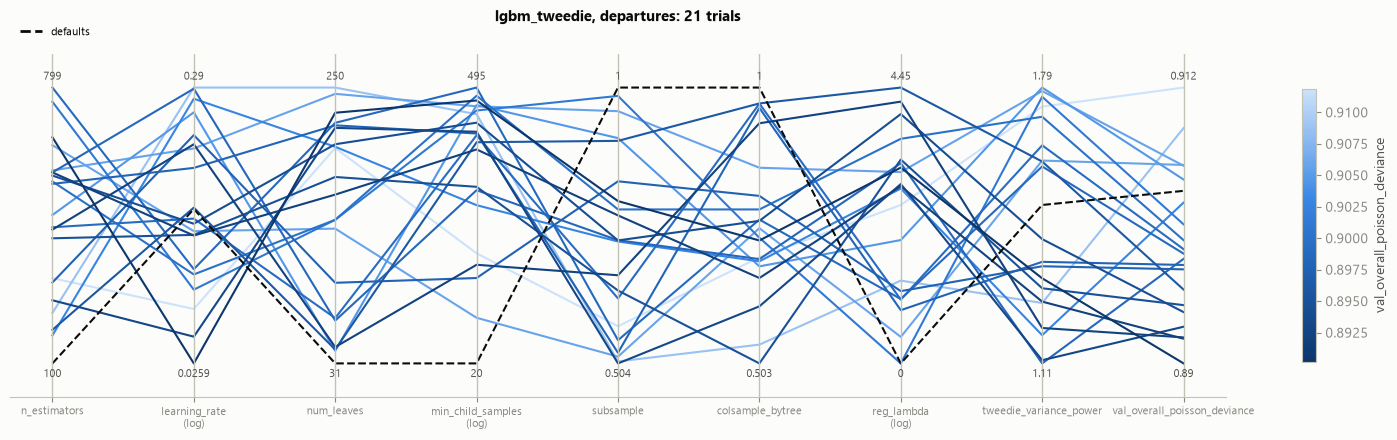

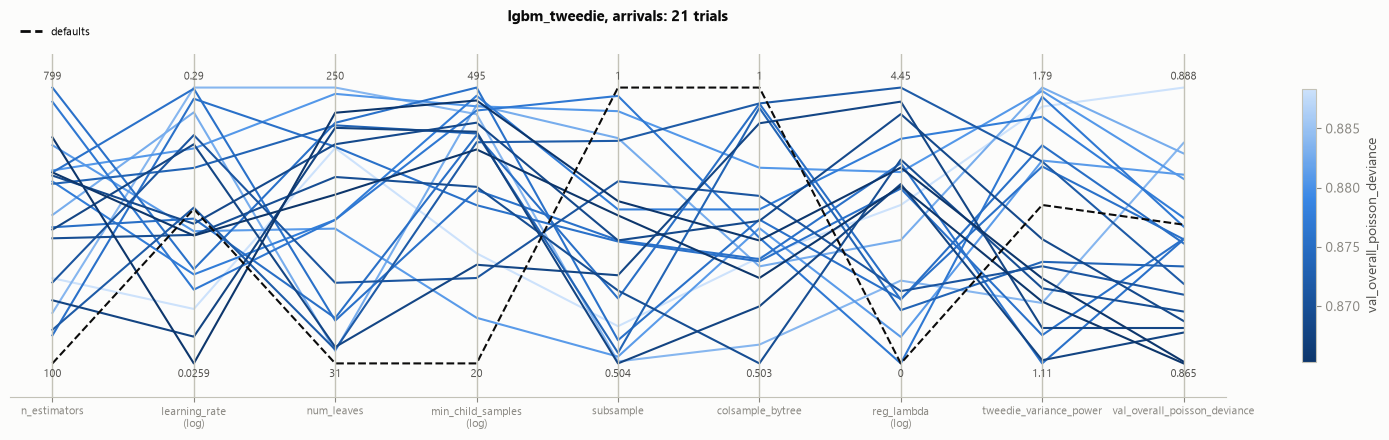

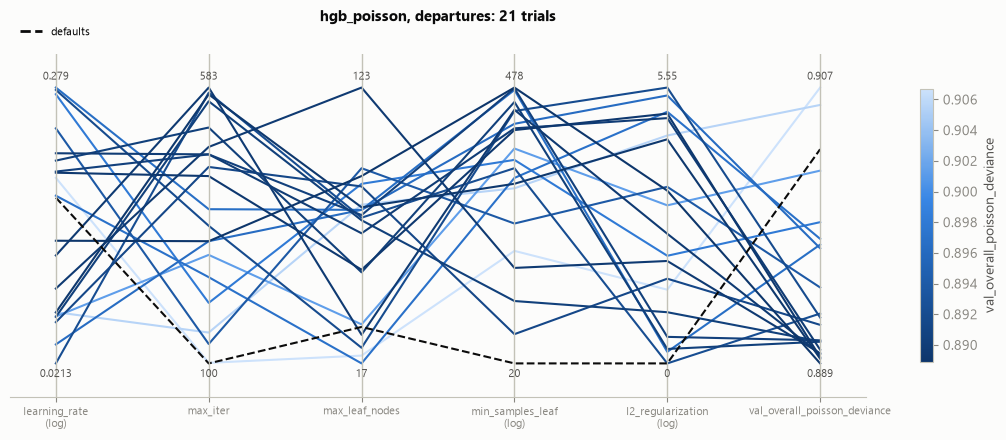

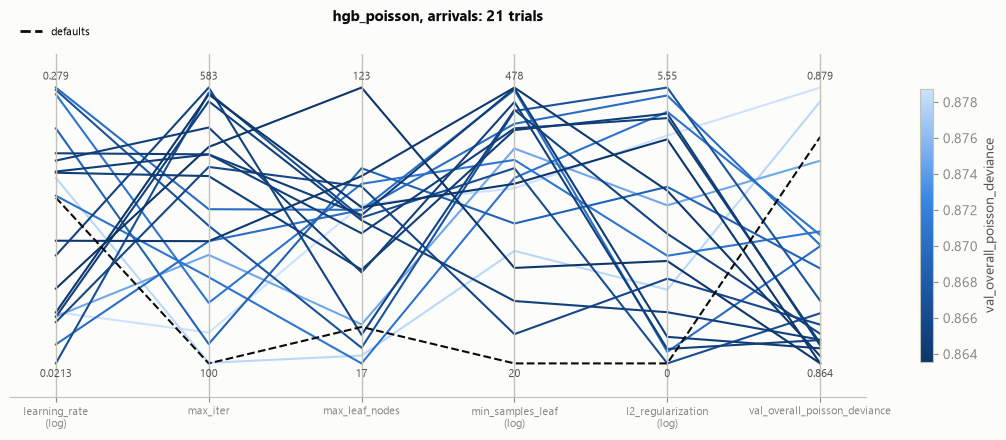

In [9]:
for name, target in KEYS:
    plots.plot_parallel_coordinates(
        trials[name, target][[*space[name], OBJECTIVE]],
        OBJECTIVE,
        f"{name}, {target}: {len(trials[name, target])} trials",
        highlight=DEFAULTS_RUN,
    )

**Result → action.**
- **The defaults are among the worst trials:** they rank 15th-19th of 21 on the validation deviance. The dashed line sits at the edges of most axes: 100 iterations, the smallest trees and no regularization.
- **The dark lines (the best trials) share two traits.** They keep more iterations, and for `lgbm_tweedie` they have a Tweedie variance power below 1.5 and some L2. Most other axes show dark lines spread over the whole range.
- **The spread is narrow:** for each model and target, the best and the worst trial are only 1.8-2.7% apart on the deviance. No region of the space breaks the model.

→ One range may be too narrow: many `hgb_poisson` trials used every iteration their `max_iter` (100-599) allowed. Section 5 checks whether that cost anything, and measures which params matter.

## 4. Contour plots

The validation deviance interpolated over the step size and the tree size, the two params that interact most in boosting: a smaller step needs more and larger trees for the same fit. Each point is a trial, and the cross is the defaults. MLflow's **Contour Plot** in the same comparison view shows the same surface.

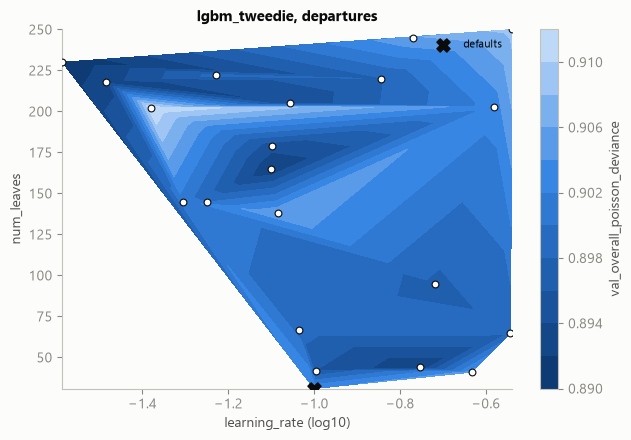

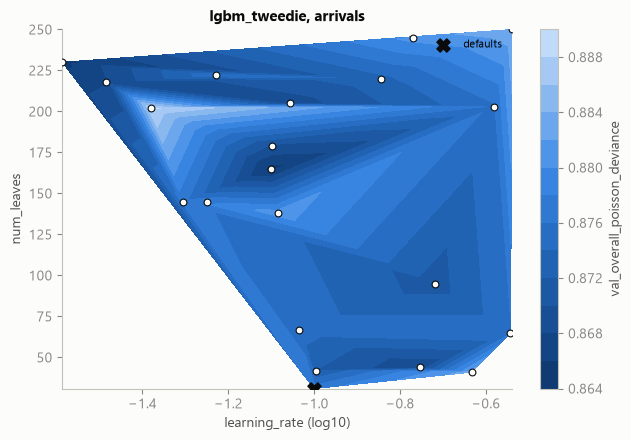

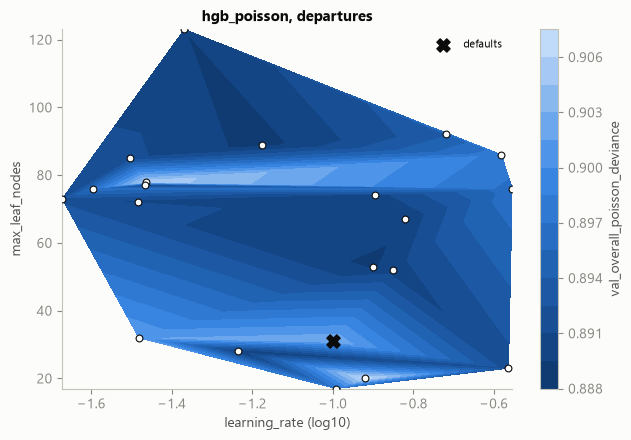

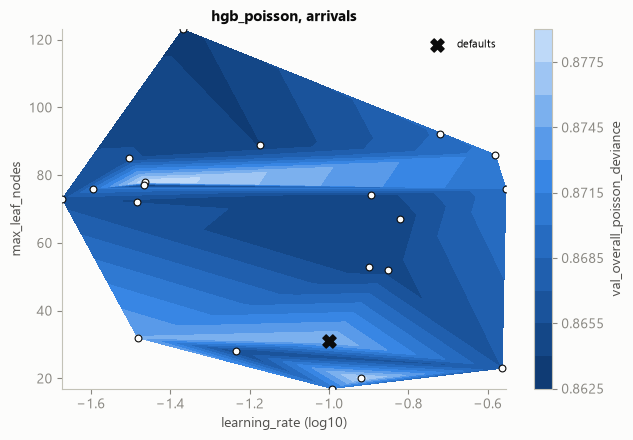

In [10]:
for name, target in KEYS:
    x, y = CONTOUR[name]
    plots.plot_contour(
        trials[name, target], x, y, OBJECTIVE, f"{name}, {target}", highlight=DEFAULTS_RUN
    )

**Result → action.**
- **For `lgbm_tweedie`** the low-deviance region lies at small learning rates with large trees (the best trial: 0.026 and 230 leaves). **For `hgb_poisson`** the dark region is broad: most combinations above 50 leaves do about equally well. With 21 points, the interpolation between them is coarse, and the stripes are artefacts of the triangulation rather than real structure.
- **The defaults (×) lie away from the darkest regions** for every model and target. Their interpolated colour can differ from their own score, since the triangulation averages them with their neighbours.

→ The contours confirm the direction of section 3 but cannot resolve the optimum more finely. More trials would refine it, but section 6 shows that the gain to win is small.

## 5. The effect of each hyperparameter

The deviance of every trial against each param, and the rank correlation between them. The correlation uses the 20 random trials only: the defaults ran without early stopping. A random search varies all the params at once, so a single panel mixes the effect of its param with that of the others. A clear trend across trials is still informative, but a flat panel only says that the param matters less than the rest.

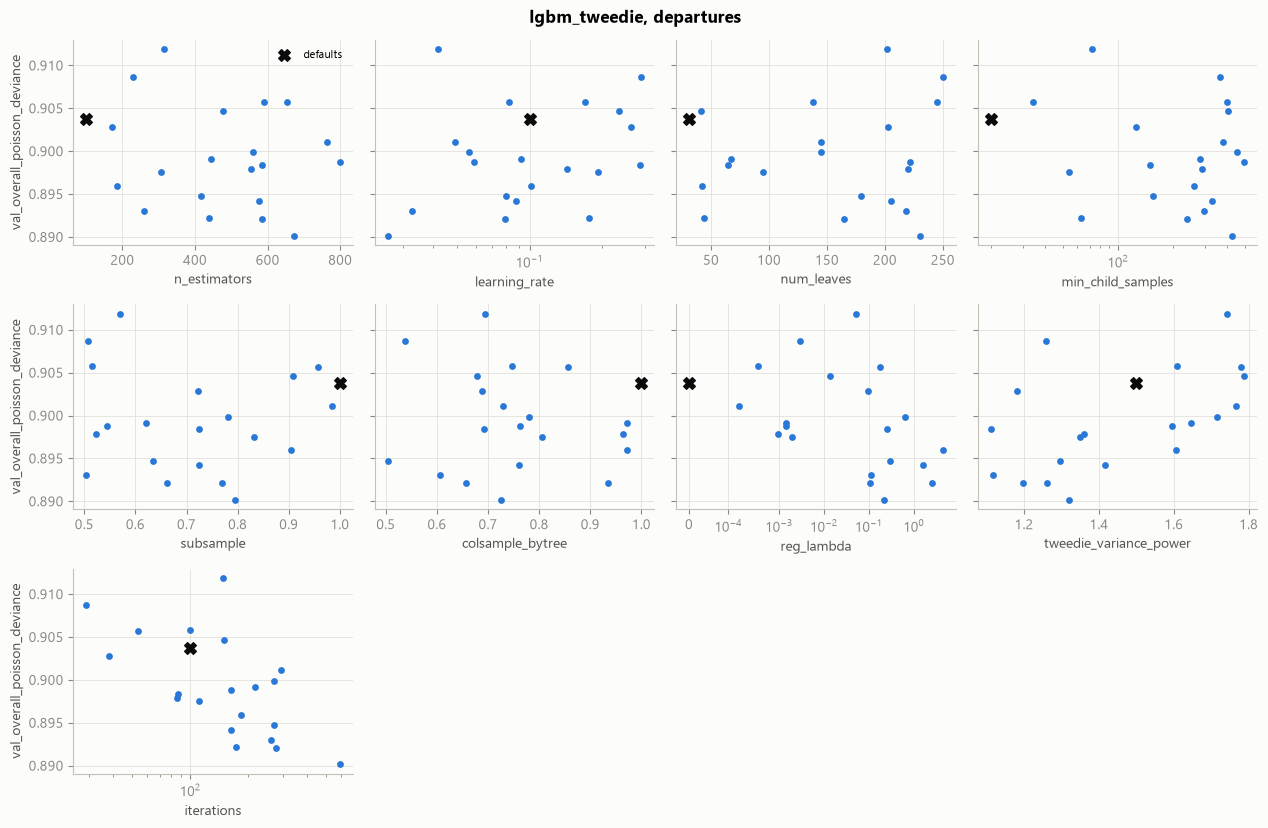

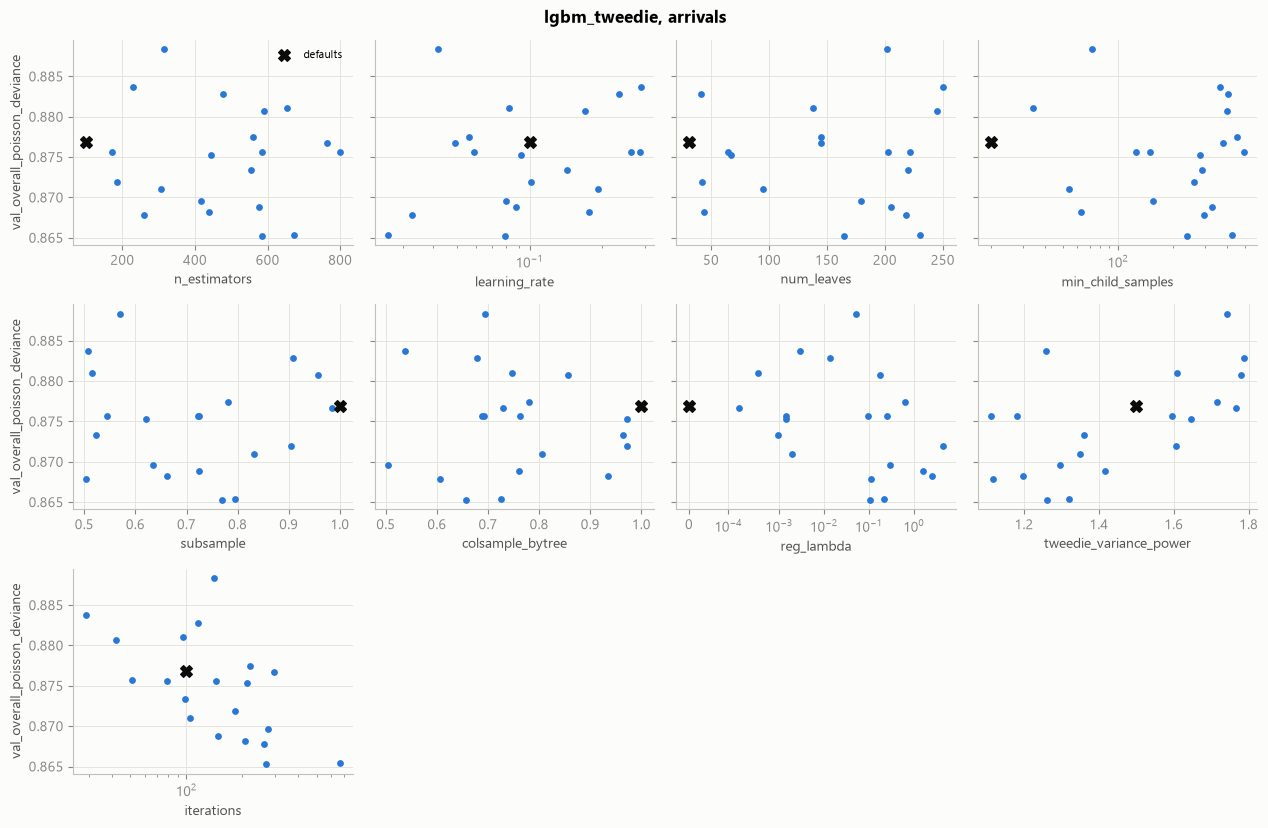

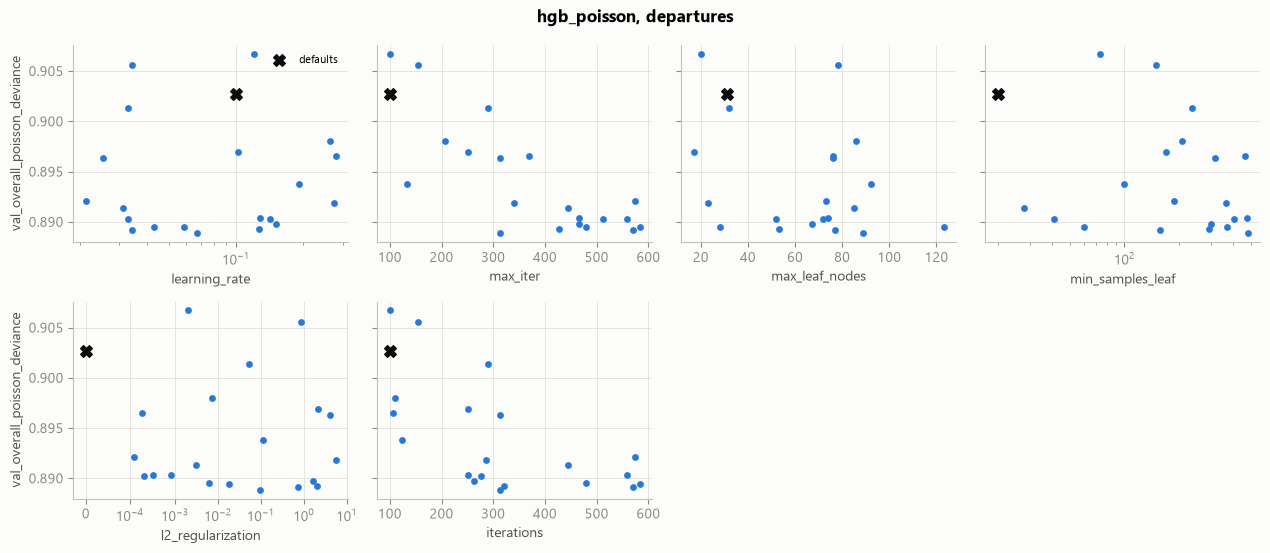

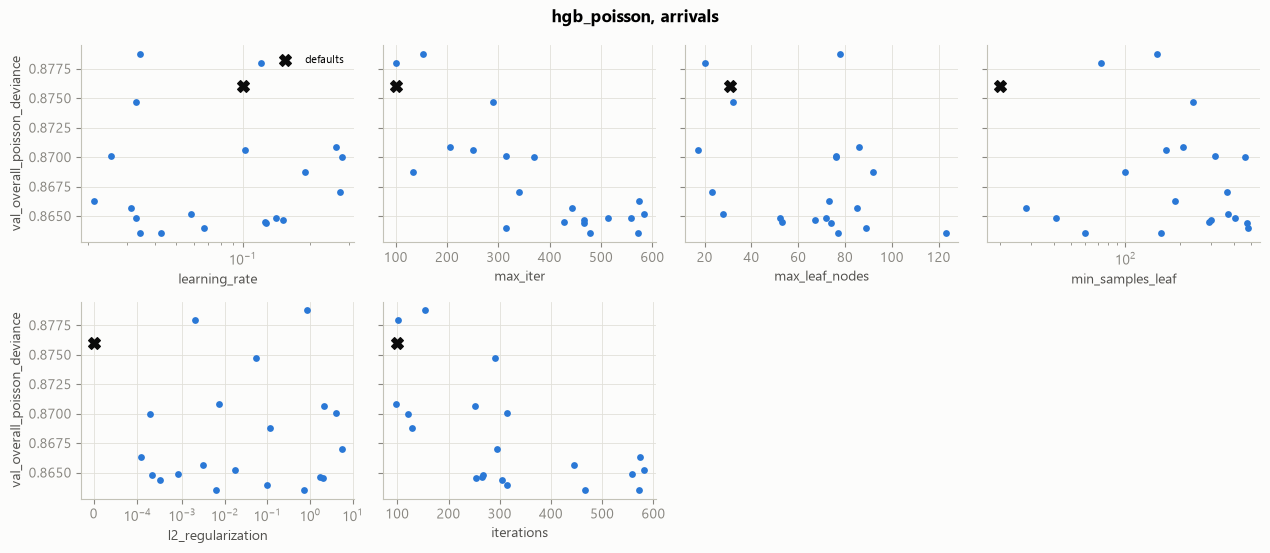

In [11]:
for name, target in KEYS:
    plots.plot_param_effects(
        trials[name, target][[*space[name], "iterations", OBJECTIVE]],
        OBJECTIVE,
        f"{name}, {target}",
        highlight=DEFAULTS_RUN,
    )

In [12]:
pd.DataFrame(
    {
        key: t.drop(DEFAULTS_RUN)[[*space[key[0]], "iterations"]].corrwith(
            t.drop(DEFAULTS_RUN)[OBJECTIVE], method="spearman"
        )
        for key, t in trials.items()
    }
).round(2).rename_axis(columns=["model", "target"])

model                  lgbm_tweedie          hgb_poisson         
target                   departures arrivals  departures arrivals
colsample_bytree              -0.05    -0.05         NaN      NaN
iterations                    -0.59    -0.59       -0.66    -0.58
l2_regularization               NaN      NaN       -0.05     0.10
learning_rate                  0.27     0.26        0.05     0.03
max_iter                        NaN      NaN       -0.70    -0.70
max_leaf_nodes                  NaN      NaN       -0.18    -0.26
min_child_samples              0.02     0.11         NaN      NaN
min_samples_leaf                NaN      NaN       -0.25    -0.20
n_estimators                  -0.05    -0.00         NaN      NaN
num_leaves                     0.06     0.02         NaN      NaN
reg_lambda                    -0.49    -0.42         NaN      NaN
subsample                     -0.08    -0.03         NaN      NaN
tweedie_variance_power         0.51     0.55         NaN      NaN

**Result → action.**
- **The number of boosting iterations matters most:** its rank correlation with the deviance is -0.58 to -0.66 for every model and target, and -0.70 for `max_iter`, the cap HGB sets. The default 100 iterations underfit. The best trials kept 269-593.
- **For `hgb_poisson` the cap bound:** in 13 of 21 trials (departures) and 11 of 21 (arrivals) every fold used all `max_iter` iterations, the best trials included. Still, trials that stopped on their own at 250-320 iterations with a higher learning rate score within 0.0004 of the best. The deviance has flattened, so a higher cap would gain little.
- **For `lgbm_tweedie`** the Tweedie variance power is next: +0.51/+0.55, so a power closer to 1 (closer to a Poisson loss) does better. L2 regularization follows: -0.49/-0.42, so more L2 does better. The learning rate (+0.27) mostly acts through the iterations it allows.
- **For `hgb_poisson`** the leaf sizes help a little: `min_samples_leaf` -0.25/-0.20 and `max_leaf_nodes` -0.18/-0.26. The learning rate and L2 show almost no effect (|ρ| ≤ 0.10).
- The other params (`subsample`, `colsample_bytree`, `num_leaves`, `min_child_samples`) are within ±0.11. They have no measurable effect in this range.

→ For later retraining, the search could fix the params without effect, and it should not cap the iterations at 100. The variance power suggests that `lgbm_tweedie` moves towards `lgbm_poisson`, which 2.02 had shown to be close.

## 6. Defaults against tuned

The acceptance criterion of the issue: the tuned models must improve the validation Poisson deviance over the defaults of `2.02`, or the notebook must explain why they do not. Both are scored on the same three folds.

The success criterion of `2.02` is stated in WAPE, so the table also checks that tuning does not lose on the peak-hour WAPE or on the daily WAPE of group 1, the quietest stations, where `2.02` found the smallest margin over the seasonal naive.

In [13]:
comparison = pd.DataFrame(
    {
        key: {
            **{(m, "defaults"): run.data.metrics[f"default_{m}"] for m in VAL_METRICS},
            **{(m, "tuned"): run.data.metrics[m] for m in VAL_METRICS},
        }
        for key, run in parents.items()
    }
).T.rename_axis(["model", "target"])
for m in VAL_METRICS:
    comparison[(m, "change")] = comparison[(m, "tuned")] / comparison[(m, "defaults")] - 1
comparison = comparison[VAL_METRICS]
comparison.style.format("{:.4f}").format("{:+.1%}", subset=[(m, "change") for m in VAL_METRICS])

In [14]:
pd.DataFrame(
    {
        key: {
            "deviance improved": row[(OBJECTIVE, "change")] < 0,
            "peak WAPE not worse": row[("val_peak_wape", "change")] <= 0,
            "group-1 daily WAPE not worse": row[("val_group_1_daily_wape", "change")] <= 0,
        }
        for key, row in comparison.iterrows()
    }
).T

deviance improved  peak WAPE not worse  \
lgbm_tweedie departures               True                 True   
             arrivals                 True                 True   
hgb_poisson  departures               True                 True   
             arrivals                 True                 True   

                         group-1 daily WAPE not worse  
lgbm_tweedie departures                         False  
             arrivals                            True  
hgb_poisson  departures                          True  
             arrivals                            True

The improvement per fold: a configuration that wins on average but loses in one month would be less trustworthy.

In [15]:
per_fold = {}
for key, runs in trial_runs.items():
    best = trials[key][OBJECTIVE].idxmin()
    by_name = runs.set_index("tags.mlflow.runName")["run_id"]
    for label, run_name in (("defaults", DEFAULTS_RUN), ("tuned", best)):
        history = client.get_metric_history(by_name[run_name], f"fold_{OBJECTIVE}")
        for m in sorted(history, key=lambda m: m.step):
            per_fold[*key, str(folds[m.step].month), label] = m.value
per_fold = pd.Series(per_fold).unstack()
per_fold["change"] = per_fold["tuned"] / per_fold["defaults"] - 1
per_fold.rename_axis(["model", "target", "fold"]).style.format(
    {"defaults": "{:.4f}", "tuned": "{:.4f}", "change": "{:+.2%}"}
)

The tuned params next to the defaults. `iterations` is what the refit on the whole training split uses: the mean of the iterations early stopping kept in the three folds.

In [16]:
params = {}
for key, t in trials.items():
    best = t[OBJECTIVE].idxmin()
    for label, run_name in (("defaults", DEFAULTS_RUN), ("tuned", best)):
        params[(*key, label)] = t.loc[run_name, [*space[key[0]], "iterations"]]
pd.DataFrame(params).rename_axis(columns=["model", "target", ""]).round(4)

model                  lgbm_tweedie                              hgb_poisson  \
target                   departures           arrivals            departures   
                           defaults     tuned defaults     tuned    defaults   
colsample_bytree                1.0    0.7247      1.0    0.6572         NaN   
iterations                    100.0  593.0000    100.0  269.0000       100.0   
l2_regularization               NaN       NaN      NaN       NaN         0.0   
learning_rate                   0.1    0.0259      0.1    0.0793         0.1   
max_iter                        NaN       NaN      NaN       NaN       100.0   
max_leaf_nodes                  NaN       NaN      NaN       NaN        31.0   
min_child_samples              20.0  426.0000     20.0  241.0000         NaN   
min_samples_leaf                NaN       NaN      NaN       NaN        20.0   
n_estimators                  100.0  673.0000    100.0  584.0000         NaN   
num_leaves                     31.0  230.0000     31.0  165.0000         NaN   
reg_lambda                      0.0    0.2136      0.0    0.1052         NaN   
subsample                       1.0    0.7956      1.0    0.7699         NaN   
tweedie_variance_power          1.5    1.3198      1.5    1.2624         NaN   

model                                                
target                           arrivals            
                           tuned defaults     tuned  
colsample_bytree             NaN      NaN       NaN  
iterations              314.0000    100.0  571.0000  
l2_regularization         0.0964      0.0    0.7265  
learning_rate             0.0669      0.1    0.0343  
max_iter                314.0000    100.0  571.0000  
max_leaf_nodes           89.0000     31.0   77.0000  
min_child_samples            NaN      NaN       NaN  
min_samples_leaf        478.0000     20.0  158.0000  
n_estimators                 NaN      NaN       NaN  
num_leaves                   NaN      NaN       NaN  
reg_lambda                   NaN      NaN       NaN  
subsample                    NaN      NaN       NaN  
tweedie_variance_power       NaN      NaN       NaN

The cost of the refitted models next to the default models of `2.02` (the latest `train-<model>-<target>` runs, fitted on the same training split).

In [17]:
cost = {}
for (name, target), run in parents.items():
    default = mlflow.search_runs(
        experiment_names=[MLFLOW_EXPERIMENT_NAME],
        filter_string=f"tags.mlflow.runName = '{TRAIN_PREFIX}-{name}-{target}' and status = 'FINISHED'",
        order_by=["start_time DESC"],
        max_results=1,
        output_format="list",
    )[0]
    for label, r in (("defaults (2.02)", default), ("tuned", run)):
        cost[name, target, label] = {
            "fit_seconds": r.data.metrics["fit_seconds"],
            "model_size_mb": r.data.metrics["model_size_mb"],
        }
pd.DataFrame(cost).T.rename_axis(["model", "target", ""]).round(1)

fit_seconds  model_size_mb
model        target                                                
lgbm_tweedie departures defaults (2.02)         75.3            0.9
                        tuned                  819.9           16.1
             arrivals   defaults (2.02)         76.3            0.9
                        tuned                  310.9            5.5
hgb_poisson  departures defaults (2.02)        107.9            1.3
                        tuned                  366.5            5.1
             arrivals   defaults (2.02)        106.2            1.3
                        tuned                  617.2            8.1

**Result → action.**
- **The acceptance criterion is met:** the tuned configurations lower the validation Poisson deviance in all four cases, by 1.3-1.5%. Departures: 0.9037 → 0.8901 (`lgbm_tweedie`) and 0.9027 → 0.8889 (`hgb_poisson`). Arrivals: 0.8769 → 0.8653 and 0.8760 → 0.8635.
- **They win in every fold:** each of the three months improves by 0.009-0.016, so the gain is not one good month.
- **The success-criterion metrics move with the deviance.** Peak WAPE falls by 0.9-1.5% and overall WAPE by 1.0-1.4% in all four cases.
- **One exception:** the daily WAPE of group 1 for `lgbm_tweedie` / departures, 0.2983 → 0.3003 (+0.7%). It is not a reason to change the choice: the difference is 0.002, while on the test split the model's margin there over the seasonal naive was about 0.09 (0.32 against 0.41). Choosing another trial on this metric after seeing the results would also bias the validation score. The other three cases improve in group 1 by 0.2-1.4%.
- **The cost grows:** the tuned models take 3-11 times longer to fit (5-14 minutes) and are 4-18 times larger (5-16 MB), because they use more and larger trees. That still fits the nightly batch of the canvas.
- **The two finalists are as close as in 2.02.** `hgb_poisson` has the slightly lower deviance (0.8889 against 0.8901, and 0.8635 against 0.8653), which is within the spread among the top trials.

→ The tuned models replace the defaults. The validation cannot separate the two finalists, so both go to the 12-fold backtest (`2.04`), which decides the champion per target. The backtest must check the group-1 daily WAPE of `lgbm_tweedie` for departures.

## 7. The refitted models

The backtest (`2.04`) and the Model Registry (`2.05`) load the model of each parent run. It must carry the tuned params, with the iterations of the refit, and give valid count forecasts. The check uses the hours of the last training month, so the test months stay untouched.

In [18]:
check_rows = model_inputs(load_features(end=TEST_START, start=CHECK_MONTH))
sample = check_rows.sample(10_000, random_state=SEED)
for (name, target), run in parents.items():
    model = mlflow.sklearn.load_model(f"runs:/{run.info.run_id}/{MODEL_ARTIFACT}")
    logged = model_params(model)
    best = trials[name, target].loc[trials[name, target][OBJECTIVE].idxmin()]
    for param in space[name]:
        if param != ITERATIONS[type(model[-1])]:
            assert np.isclose(logged[param], best[param]), (name, target, param)
    assert logged[ITERATIONS[type(model[-1])]] == best["iterations"]
    assert logged.get("early_stopping", False) is False  # the refit uses a fixed count
    y_pred = model.predict(sample)
    assert np.isfinite(y_pred).all() and (y_pred >= 0).all()
print(f"{len(parents)} refitted models carry the tuned params and forecast {len(sample):,} hours of {CHECK_MONTH}")

4 refitted models carry the tuned params and forecast 10,000 hours of 2025-09


## Findings and next steps

**Output**
- 4 MLflow parent runs `tune-<model>-<target>` (`lgbm_tweedie` and `hgb_poisson`, departures and arrivals), with 84 nested trial runs.
  - Each trial logs its params, the iterations it kept, the mean validation metrics and the per-fold metrics as steps.
  - Each parent logs the search settings, the best trial's params and metrics, the defaults' metrics as `default_val_*`, and the model refitted on the whole training split (skops, with a signature and an input example).
- `python -m team2_mlops2026.modeling.train tune` reproduces them in about 4 hours on a laptop.

**Decisions**
- Tuning stays inside the training split: three monthly folds (2025-07 to 2025-09) with early stopping on the 14 days before each month. The test months from 2025-10 on were never read. The choices are justified in `references/ml-canvas.md` §8.
- The best trial is chosen on the validation Poisson deviance, the objective set before the search. The WAPE metrics are checked, not optimized.

**What it means for the next issues**
- **Tuning helps, but not by much:** 1.3-1.5% on the deviance and about 1% on the peak WAPE. Most of the gain comes from more boosting iterations. The features of 2.02 mattered far more than the hyperparameters.
- **The backtest (`2.04`, #26)** takes the refitted models of these parent runs. It should:
  - compare the two finalists, which are within 0.2% of each other on validation
  - report the group-1 daily WAPE of `lgbm_tweedie` for departures, the one metric that did not improve
  - weigh the larger and slower tuned models against their gain.
- **The Model Registry (`2.05`, #27)** registers the champion from the parent run whose model wins the backtest.